In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
import numpy as np
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


In [2]:

df = pd.read_csv(
    "weather_dataset_2024_2026.csv",
    parse_dates=["time"]
)
models = ["ECMWF", "GFS", "ICON_EU"]
features = {
    "Temperature":   ("actual_temperature",   "temperature",   "°C"),
    "Precipitation": ("actual_precipitation", "precipitation", "mm"),
    "Wind speed":    ("actual_wind_speed",    "wind_speed",    "m/s"),
}

**Temperatuur**

In [3]:
# MAE and RMSE
for model in models:
    print(f"\n{model}")
    print("MAE", mean_absolute_error(df["actual_temperature"], df[f"temperature_{model}"]))
    print("RMSE", root_mean_squared_error(df["actual_temperature"], df[f"temperature_{model}"]))


ECMWF
MAE 1.2416968599033817
RMSE 1.595562990307386

GFS
MAE 1.6508303140096618
RMSE 2.074934155872839

ICON_EU
MAE 1.0934480676328502
RMSE 1.4055510205956896


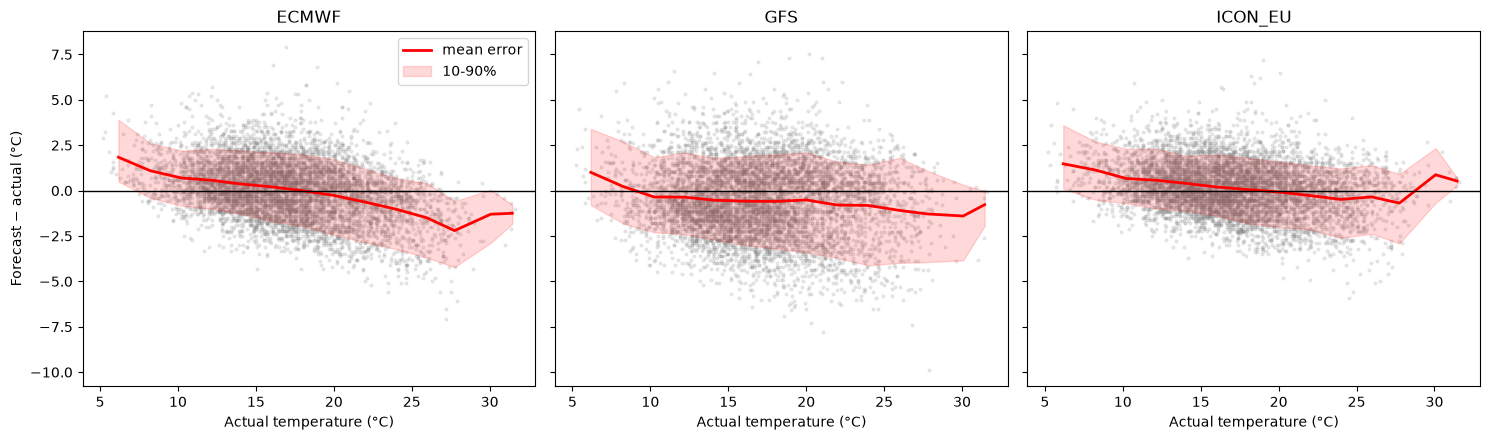

In [4]:
for m in models:
    df[f"err_{m}"] = df[f"temperature_{m}"] - df["actual_temperature"]

bins = np.arange(np.floor(df["actual_temperature"].min()),
                 np.ceil(df["actual_temperature"].max()) + 2, 2)
df["t_bin"] = pd.cut(df["actual_temperature"], bins)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, m in zip(axes, models):
    ax.scatter(df["actual_temperature"], df[f"err_{m}"],
               s=4, alpha=0.15, color="gray")

    g = df.groupby("t_bin", observed=True)
    x = g["actual_temperature"].mean()
    ax.plot(x, g[f"err_{m}"].mean(), color="red", lw=2, label="mean error")
    ax.fill_between(x, g[f"err_{m}"].quantile(0.1),
                    g[f"err_{m}"].quantile(0.9),
                    color="red", alpha=0.15, label="10-90%")

    ax.axhline(0, color="black", lw=1)
    ax.set_title(m)
    ax.set_xlabel("Actual temperature (°C)")
axes[0].set_ylabel("Forecast − actual (°C)")
axes[0].legend()
plt.tight_layout()
plt.show()

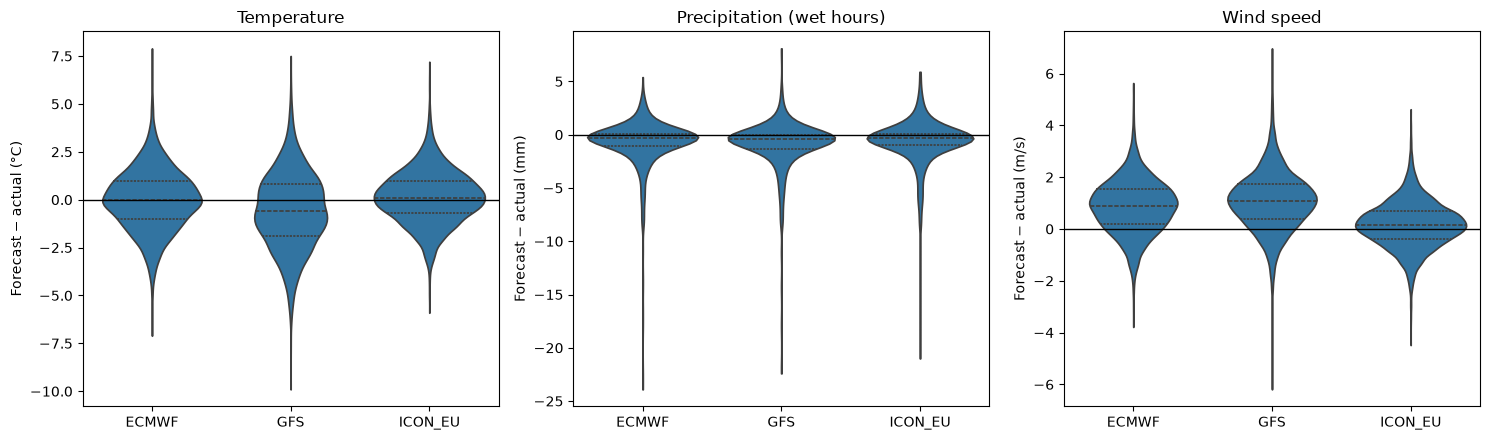

In [5]:
rows = []
for feat, (act, prefix, unit) in features.items():
    for m in models:
        rows.append(pd.DataFrame({
            "feature": feat,
            "model": m,
            "error": df[f"{prefix}_{m}"] - df[act],
            "actual": df[act],
        }))
long = pd.concat(rows, ignore_index=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (feat, (_, _, unit)) in zip(axes, features.items()):
    d = long[long["feature"] == feat].dropna(subset=["error"])
    # choose only "wet" hours
    if feat == "Precipitation":
        d = d[d["actual"] > 0.1]
    sns.violinplot(data=d, x="model", y="error", ax=ax,
                   inner="quartile", cut=0)
    ax.axhline(0, color="black", lw=1)
    ax.set_title(feat + (" (wet hours)" if feat == "Precipitation" else ""))
    ax.set_ylabel(f"Forecast − actual ({unit})")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

In [6]:
models = ["ECMWF", "GFS", "ICON_EU"]

actual = (df["actual_precipitation"] > 0).astype(int)

results = []

for model in models:
    predicted = (df[f"precipitation_{model}"] > 0).astype(int)

    results.append({
        "Model": model,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "F1-score": f1_score(actual, predicted, zero_division=0)
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1-score
0,ECMWF,0.743,0.260,0.815,0.394
1,GFS,0.800,0.287,0.641,0.397
2,ICON_EU,0.843,0.358,0.669,0.466


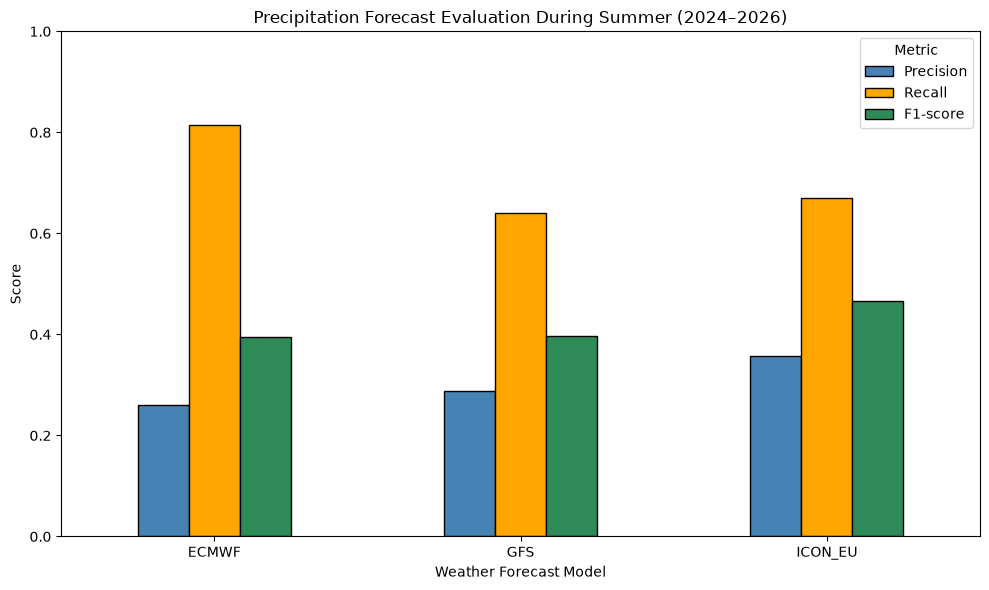

In [7]:
results_df.set_index("Model")[
    ["Precision", "Recall", "F1-score"]
].plot(
    kind="bar",
    figsize=(10, 6),
    color=["steelblue", "orange", "seagreen"],
    edgecolor="black",
    rot=0
)

plt.title("Precipitation Forecast Evaluation During Summer (2024–2026)")
plt.xlabel("Weather Forecast Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(title="Metric")

plt.tight_layout()
plt.show()